# 12-FreeRTOS二值信号量与任务同步


## 1. 本篇内容与学习目标

本篇是《FreeRTOS 从入门到实战》十七篇笔记中的第12篇，对应 `17二值信号量.pptx`，原课主题为**二进制信号量**。

课程从二值信号量的0/1计数特性开始，解释它如何在任务之间传递通知，再通过 `xSemaphoreCreateBinary()`、`xSemaphoreTake()` 和 `xSemaphoreGive()` 三个核心 API 完成按键唤醒 LED 任务的案例。

| 课件主线 | 本篇学习内容 |
|---|---|
| 基本概念 | 0/1计数、无钥匙/有钥匙和“通知而非数据” |
| 核心作用 | 任务同步与简单的资源互斥语义 |
| 核心 API | 创建、获取、释放，以及阻塞时间和返回值 |
| 实战案例 | 按键释放信号量，LED 任务获取后闪烁 |

本篇以主课件第1—19页为教学内容，第20页为品牌结束页；另参考同名副本第21页的核心小结。副本第22页为品牌结束页。示例代码用于解释课程流程，没有把未展示的板级初始化细节写成确定事实，也未声称完成开发板编译、下载或运行。

配置和 API 边界的校正参考官方 FreeRTOS-Kernel V10.5.1 的 `semphr.h`、`FreeRTOS.h` 和 `tasks.c`，未确认是课程源码版本。课件中的配置宏拼写和两种 LED 示例行为，在对应章节就地说明。


## 2. 什么是二值信号量

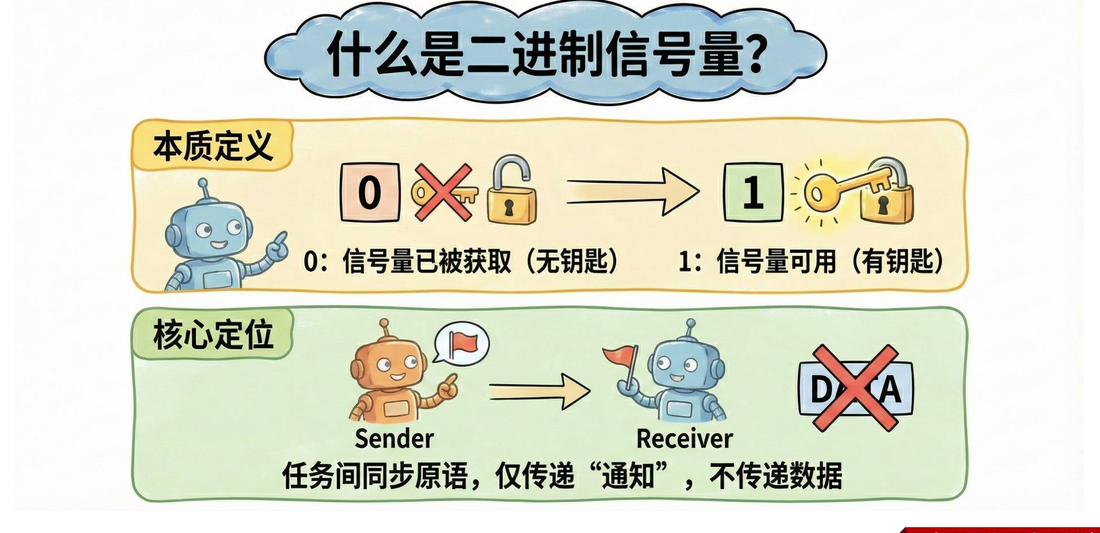

二值信号量只有两种状态，可以把它理解为一个最多放入一把钥匙的公共钥匙盒：

```text
计数值 0：没有钥匙，信号量不可用
计数值 1：有钥匙，任务可以获取
```

FreeRTOS 二值信号量主要用来传递**事件通知**，而不是传递业务数据。发送方通过 `xSemaphoreGive()` 把信号量置为可用，接收方通过 `xSemaphoreTake()` 获取它；获取成功后计数值回到0。

这个语义适合“按键已经按下”“数据已经准备好”“某个外设操作完成”等场景。若需要传递目标位置、传感器距离或结构体，应使用消息队列等数据通道；二值信号量本身不保存这些数据。


## 3. 二值信号量的核心作用

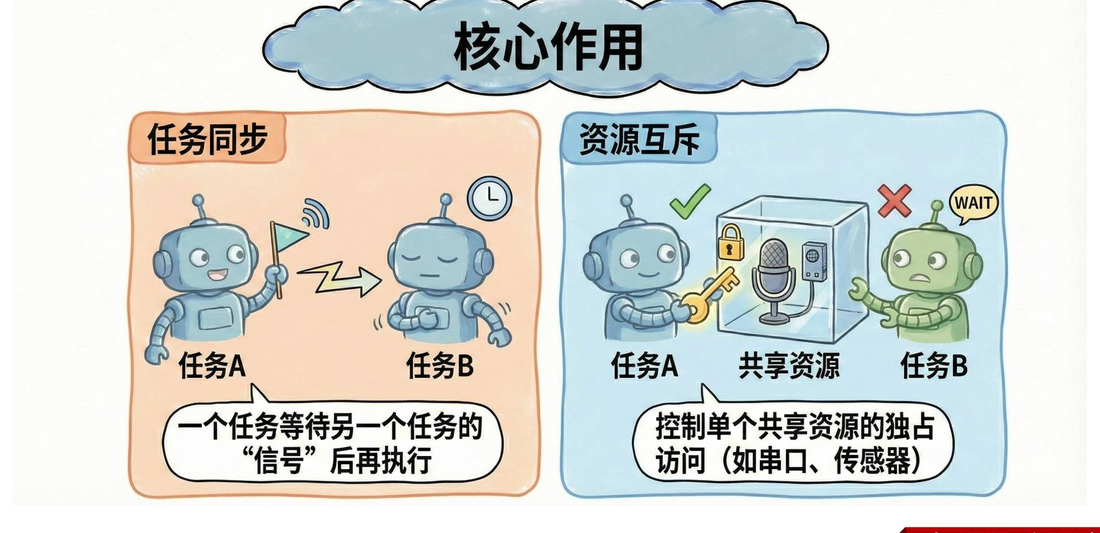

课件把二值信号量的用途归纳为两个方向：

### 任务同步

一个任务等待另一个任务或中断发出“可以继续”的信号。例如 LED 任务先阻塞等待，按键事件到达后，按键任务释放信号量，LED 任务被唤醒并执行闪烁逻辑。

### 简单互斥

当信号量代表某项资源是否可用时，任务获取成功后再访问资源，使用完毕后释放。对于需要所有权和优先级继承的严格资源保护，应优先使用互斥信号量；二值信号量更适合表达无所有权的事件同步。

同步流程可以写成：

```text
创建信号量（计数值0）
        ↓
接收任务 Take，发现无钥匙后阻塞
        ↓
发送任务 Give，计数值变为1并唤醒等待任务
        ↓
接收任务 Take，计数值回到0并执行后续逻辑
```


## 4. 创建二值信号量：`xSemaphoreCreateBinary`

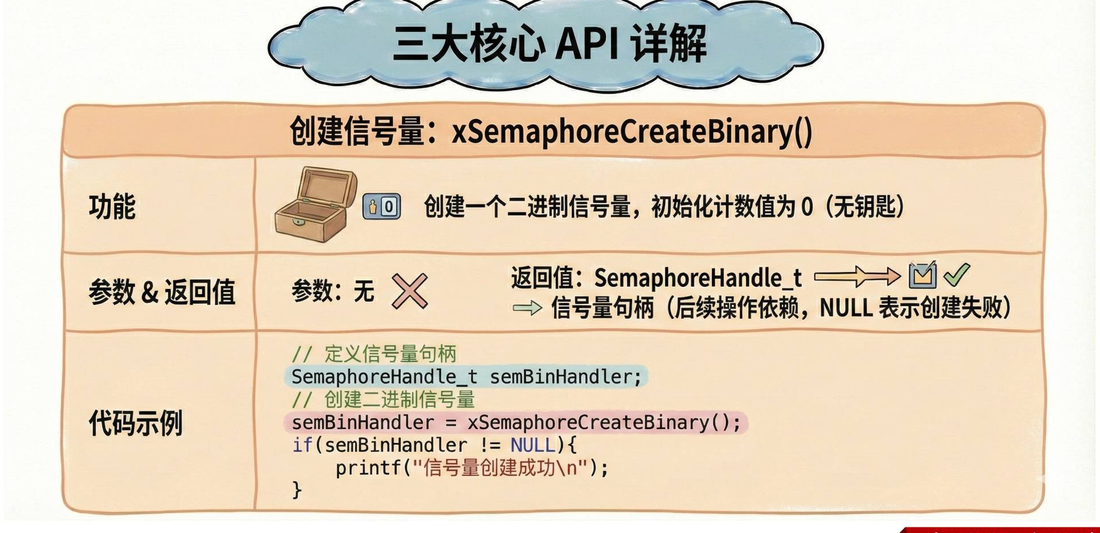

创建二值信号量使用：

```c
SemaphoreHandle_t semBinHandler;

semBinHandler = xSemaphoreCreateBinary();
if (semBinHandler == NULL) {
    // 创建失败：通常需要检查堆空间和动态内存配置
    handle_create_error();
}
```

`xSemaphoreCreateBinary()` 没有参数，返回 `SemaphoreHandle_t` 句柄。返回 `NULL` 表示创建失败，后续不能继续对无效句柄调用 Take 或 Give。

课件强调，动态创建的信号量需要从 FreeRTOS 堆中申请对象空间。如果创建失败，应检查 `configTOTAL_HEAP_SIZE`、heap 实现和系统中其他动态对象的数量。创建成功后，二值信号量的初始计数值为0，也就是默认没有“钥匙”。因此，若希望某个任务一开始就能通过 `xSemaphoreTake()`，需要在合适的初始化阶段先调用一次 `xSemaphoreGive()`。

信号量句柄应放在所有需要访问它的任务都能看到的作用域，或者通过任务参数传递。句柄的创建、使用和删除要有清晰的生命周期，不能在仍有任务等待时随意删除。


## 5. 获取信号量：`xSemaphoreTake`

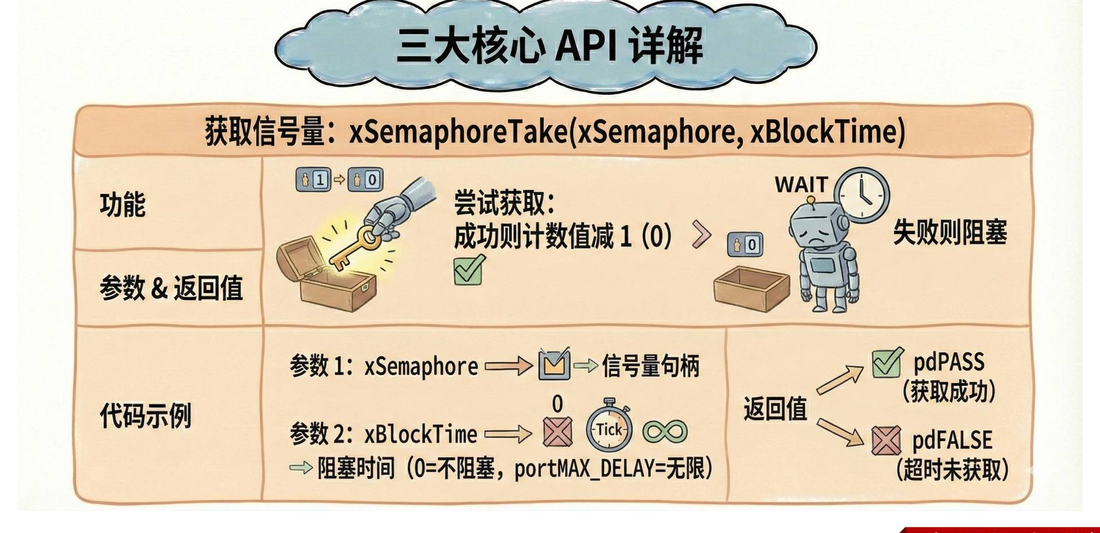

获取信号量的 API 为：

```c
BaseType_t xSemaphoreTake(
    SemaphoreHandle_t xSemaphore,
    TickType_t xBlockTime
);
```

上面是接口含义的写法；在参考版本中，`xSemaphoreTake` 是调用队列内核接口的宏。第一个参数是有效信号量句柄，第二个参数是获取失败时最多阻塞的 tick 数：

| `xBlockTime` | 行为 |
|---|---|
| `0` | 非阻塞尝试，当前没有信号量就立即返回 `pdFALSE` |
| `pdMS_TO_TICKS(500)` | 最多等待500毫秒，超时仍未获取到就返回失败 |
| `portMAX_DELAY` | 当 `INCLUDE_vTaskSuspend == 1` 时无限等待；否则是最大有限 tick 等待 |

参考版本返回 `pdTRUE` 表示成功获取，返回 `pdFALSE` 表示超时或当前不可用；课件使用的 `pdPASS` 与 `pdTRUE` 都为1，`pdFAIL` 与 `pdFALSE` 都为0。任务应该根据返回值决定是否执行后续逻辑：

```c
if (xSemaphoreTake(semBinHandler, portMAX_DELAY) == pdPASS) {
    do_after_notification();
}
```

不要在没有判断返回值的情况下直接执行“已获得许可”的代码；超时路径需要有明确处理。任务在阻塞等待信号量时不会持续占用 CPU，调度器可以运行其他就绪任务。


## 6. 释放信号量：`xSemaphoreGive`

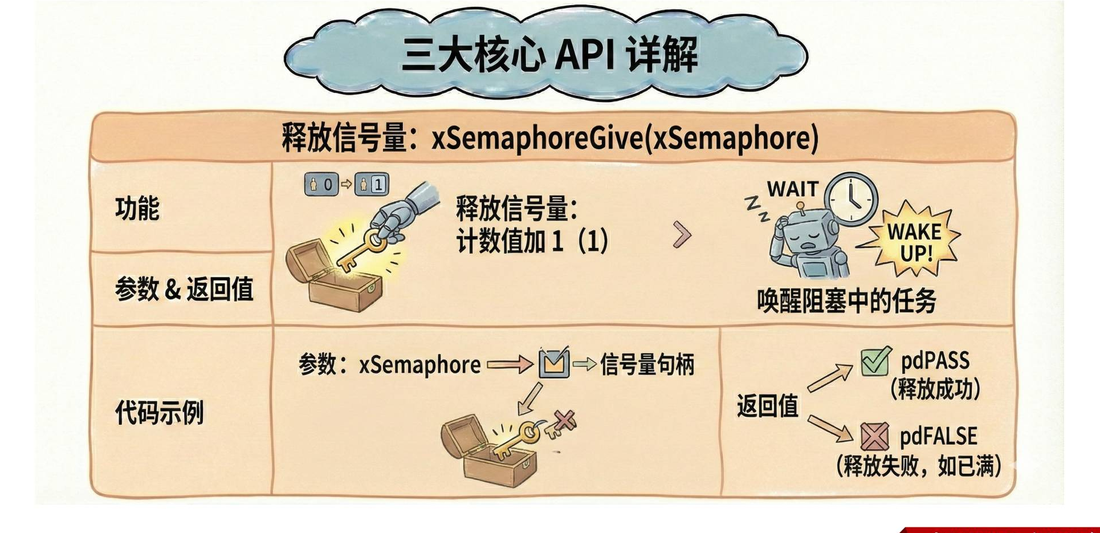

释放信号量的 API 为：

```c
BaseType_t xSemaphoreGive(SemaphoreHandle_t xSemaphore);
```

对有效句柄调用成功后，计数值从0变为1；如果有任务正在等待，内核可以将其中一个等待任务移到就绪态。就绪不等于马上执行，实际运行仍由优先级和调度决定。返回 `pdTRUE` 表示释放成功，满信号量返回 `pdFALSE`；课件采用等值的 `pdPASS` / `pdFAIL` 写法。

```c
if (xSemaphoreGive(semBinHandler) != pdPASS) {
    // 信号量已经为1，按业务记录并处理
    log_semaphore_give_failure();
}
```

二值信号量不是计数器队列。连续调用两次 Give 并不会保存“两次事件”，最多保持为1；如果必须统计多个事件发生次数，应使用计数信号量或消息队列。这个差异是二值信号量和计数信号量的关键边界。

如果释放动作来自中断服务函数，必须使用 `xSemaphoreGiveFromISR()`，并按需通过 `pxHigherPriorityTaskWoken` 请求一次任务切换。普通任务 API 与 ISR 专用 API 不能混用。

`NULL` 或已删除的句柄违反 API 前提，可能触发断言或非法访问，不能把它当成能够通过失败返回值安全处理的情况。应在调用前保证对象有效。


## 7. 阻塞时间与返回值的工程含义

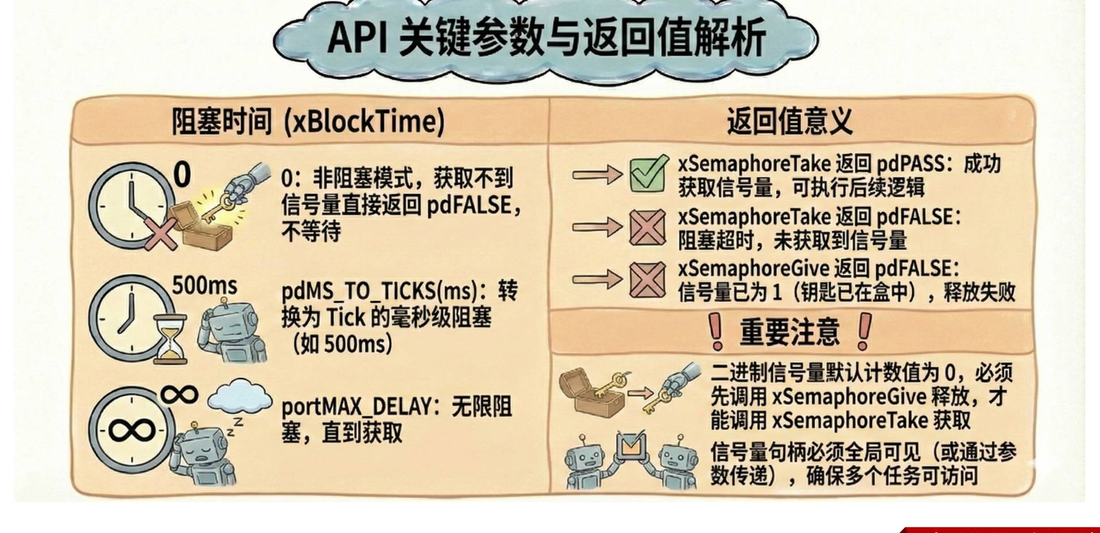

`xBlockTime` 是“等待信号量的最长时间”，不是信号量内部的计数周期，也不是任务执行时间。使用毫秒值时，应通过 `pdMS_TO_TICKS()` 转换：

```c
TickType_t wait_ticks = pdMS_TO_TICKS(500);
BaseType_t result = xSemaphoreTake(semBinHandler, wait_ticks);

if (result == pdPASS) {
    // 获取成功
} else {
    // 超时，未获取到信号量
}
```

**配置校正（官方 FreeRTOS-Kernel V10.5.1 参考版本，未确认是课程源码版本）：**主课件第18页及副本第14页写了 `configUSE_TASK_SUSPEND`，实际控制无限等待的是 `INCLUDE_vTaskSuspend`。当它为1且等待值为 `portMAX_DELAY` 时，内核不按 tick 超时；若为0，`portMAX_DELAY` 仍是有限最大值。

副本第14页还写了 `configUSE_SEMAPHORES`。参考版本没有这个二值信号量总开关，不能把它作为开启功能的依据。动态创建需要 `configSUPPORT_DYNAMIC_ALLOCATION == 1`，并包含 `FreeRTOS.h` 与 `semphr.h`、编译队列内核及合适的 heap 实现。相关写法为：

```c
// FreeRTOSConfig.h：参考配置，需与工程其他配置一起检查
#define configSUPPORT_DYNAMIC_ALLOCATION 1
#define INCLUDE_vTaskSuspend             1
```

释放端也要处理返回值。二值信号量的容量只有1：当计数已经为1时再次 Give 会失败或没有可累加的空间。若业务要求每一次按键都不能丢失，不要只依赖二值信号量保存次数，应重新评估计数信号量或消息队列。


## 8. 按键触发 LED：两种课程案例

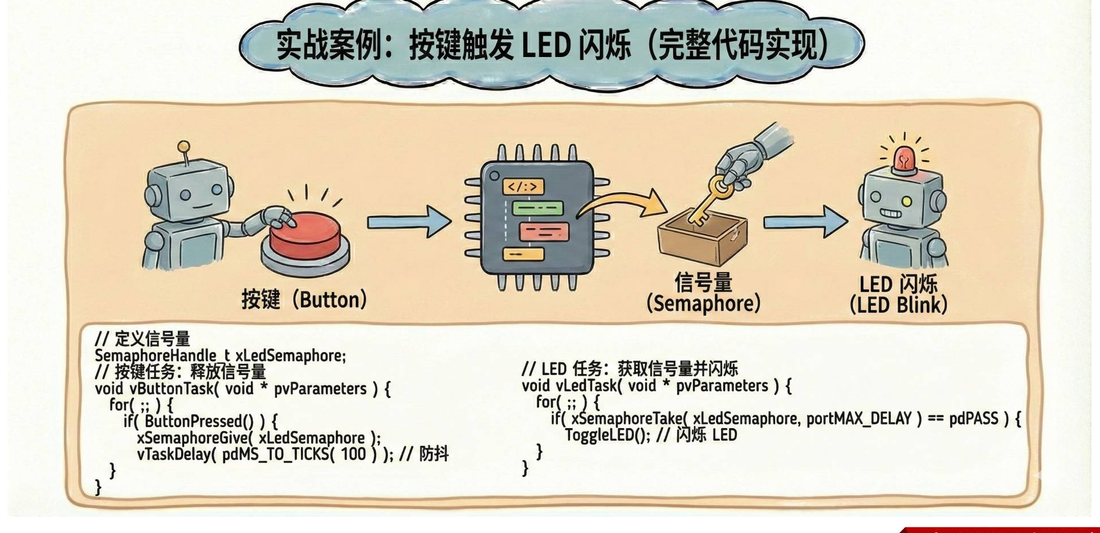

课件把按键处理和 LED 任务分开。主课件第11页的概览例把 Take 放在循环内，每获取一次就执行一次 `ToggleLED()`。以下按这个流程整理，并补充空闲扫描延时以避免按键任务忙等，属于说明性片段：

```c
static SemaphoreHandle_t xLedSemaphore;

void vButtonTask(void *pvParameters)
{
    for (;;) {
        if (ButtonPressed()) {
            xSemaphoreGive(xLedSemaphore);
            vTaskDelay(pdMS_TO_TICKS(100)); // 示例性的按键消抖
        }
        vTaskDelay(pdMS_TO_TICKS(10));
    }
}

void vLedTask(void *pvParameters)
{
    for (;;) {
        if (xSemaphoreTake(xLedSemaphore, portMAX_DELAY) == pdPASS) {
            ToggleLED();
        }
    }
}
```

初始化时先创建信号量，再创建两个任务。以下栈深度和优先级为示例值，要检查任务创建返回值，并按板级内存和实际栈使用量调整：

```c
xLedSemaphore = xSemaphoreCreateBinary();
configASSERT(xLedSemaphore != NULL);

xTaskCreate(vButtonTask, "Button", 256, NULL, 2, NULL);
xTaskCreate(vLedTask, "LED", 256, NULL, 2, NULL);
```

这里的 `ButtonPressed()`、`ToggleLED()` 是课件概览中的抽象驱动名称，实际工程要替换成板级接口。仅延时100ms不等于完整消抖：如果 `ButtonPressed()` 返回持续按下状态，长按会不断触发，应增加稳定状态判断与按下边沿检测。事件方向是按键任务 Give，LED 任务 Take；信号量不携带按键编号或 LED 模式。

主课件第12—14页的板级例则在循环外只 Take 一次。以下保留课件的 `GPIOD`、`GPIO_PIN_8`、`KEY1` 名称，补充句柄/返回值检查，并用 `vTaskDelete(NULL)` 处理异常路径，避免 FreeRTOS 任务直接 `return`：

```c
static SemaphoreHandle_t semBinHandler;

void task1(void *param)
{
    if (xSemaphoreTake(semBinHandler, portMAX_DELAY) != pdTRUE) {
        vTaskDelete(NULL);
    }

    while (1) {
        gpio_bit_reset(GPIOD, GPIO_PIN_8); // 课件中表示点亮
        vTaskDelay(pdMS_TO_TICKS(250));
        gpio_bit_set(GPIOD, GPIO_PIN_8);   // 课件中表示熄灭
        vTaskDelay(pdMS_TO_TICKS(250));
    }
}

// 仅适用于任务上下文中的按键回调
void bsp_key_press_callback(KEY key)
{
    if (key == KEY1 && semBinHandler != NULL) {
        BaseType_t result = xSemaphoreGive(semBinHandler);
        if (result != pdTRUE) {
            // 已有一个待消费信号，按业务决定记录或合并
        }
    }
}
```

这段任务在第一次按键后持续闪烁，约250ms亮、250ms灭，一个周期约500ms，受 tick 与调度延迟影响。它没有第二次 Take，也没有“再按一次暂停”的逻辑；后续 Give 不会改变持续闪烁行为。电平含义、GPIO初始化和按键回调上下文应以实际板级驱动为准。


## 9. 案例运行流程与同步原理

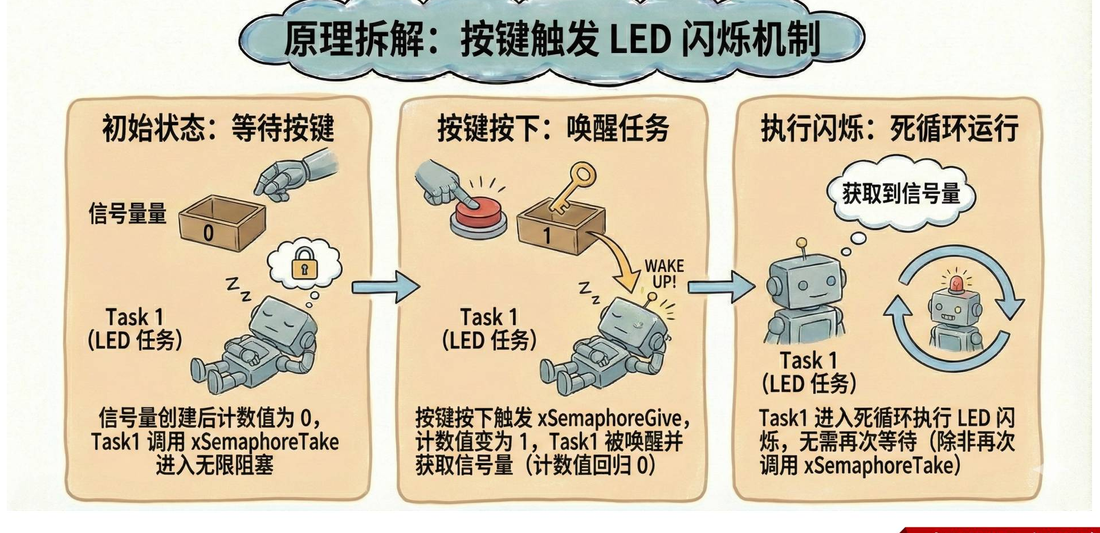

案例的状态变化如下：

1. 创建二值信号量，计数值为0；LED 任务调用 `xSemaphoreTake()`，因为没有钥匙而进入阻塞。
2. 按键任务检测到按下，调用 `xSemaphoreGive()`，计数值变为1，并唤醒等待中的 LED 任务。
3. LED 任务获取信号量，计数值回到0，执行 LED 点亮、延时、熄灭等闪烁逻辑。
4. **循环内 Take 的概览例**：每次翻转后返回下一轮等待。**循环外 Take 的板级例**：首次事件只是启动门，之后任务持续按250ms间隔改变 LED 电平，不再等待按键。

这个流程把“检测输入”和“执行动作”解耦：按键任务不需要直接操作 LED，LED 任务也不需要轮询按键状态。任务同步的核心是一个事件开关，而不是共享一个不断被读写的全局标志。

如果按键在 LED 任务处理期间连续触发，二值信号量最多保留一个未消费事件，后续重复 Give 可能丢失。需要记录每一次按键时，应使用计数信号量或消息队列，并根据按键消抖策略过滤机械抖动。


## 10. 使用二值信号量的关键注意事项

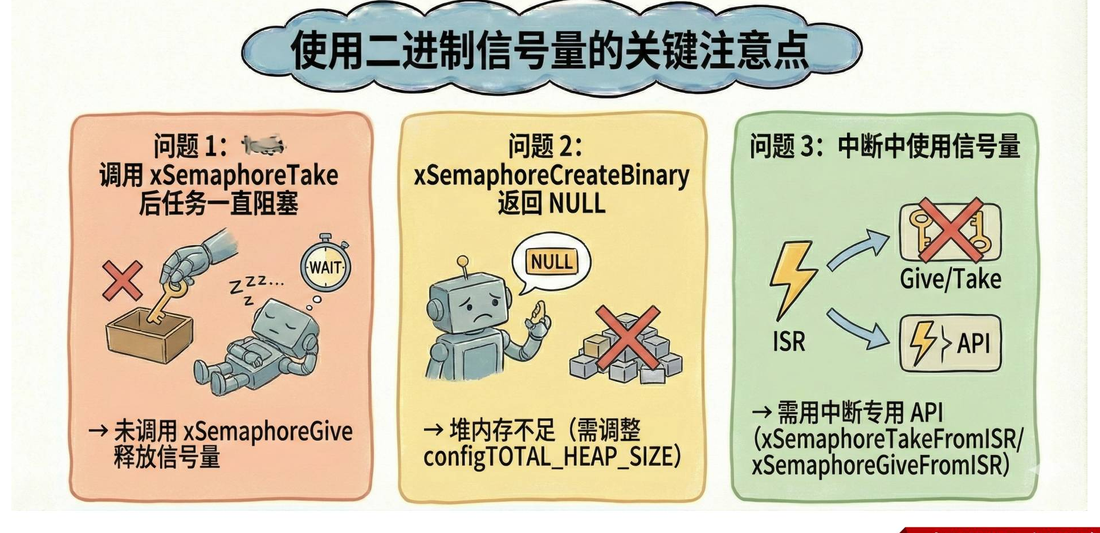

课件列出的常见问题可以整理为：

| 问题 | 原因与处理 |
|---|---|
| Take 后任务一直阻塞 | 没有任何路径调用 Give；检查事件源、初始化和句柄 |
| `xSemaphoreCreateBinary()` 返回 `NULL` | 堆空间不足或动态内存配置不合适，检查 `configTOTAL_HEAP_SIZE` 等配置 |
| 在 ISR 中调用普通 Give/Take | 通知任务通常用 `xSemaphoreGiveFromISR()`；`xSemaphoreTakeFromISR()` 只能立即尝试，不能阻塞 |
| 把二值信号量当计数器 | 0/1 只能保存一个待处理事件，必须保留每次发生次数时用计数信号量或队列 |
| 多个任务找不到同一信号量 | 句柄没有放到共享作用域，或没有通过参数传递 |
| 无限等待无法工作 | 检查 `portMAX_DELAY` 的使用条件和 `INCLUDE_vTaskSuspend` 配置；课件宏名有误 |

信号量句柄应在使用它的任务创建前完成初始化；删除信号量前，要确认没有任务正在等待或继续引用它。进入临界区可以保护非常短的句柄或状态更新，但不能用临界区替代任务之间的长期等待。

**ISR 补充（官方 V10.5.1 参考版本，未确认是课程源码版本）：**以下片段在有效句柄已创建后通知任务。清除外设中断标志和引脚消抖仍由驱动负责；Cortex-M 上，中断还必须符合第09篇讲述的 FreeRTOS 可调用 API 优先级范围。

```c
BaseType_t higher_priority_task_woken = pdFALSE;
BaseType_t sent = xSemaphoreGiveFromISR(
    semBinHandler, &higher_priority_task_woken);
if (sent != pdTRUE) {
    // 已有待消费事件，按业务决定合并或记录
}
portYIELD_FROM_ISR(higher_priority_task_woken); // 名称以所用端口为准
```

课件第18页说“多任务同步需用计数型信号量”，这里需要按语义细化：多个任务可以等待同一个二值信号量，但一次 Give 只提供一个可消费许可，不是广播。如果要保留多次事件，用计数信号量；如果每个接收任务都必须看到同一个事件，要设计各自通知或事件组等广播机制。


## 11. 本课要点与验证步骤

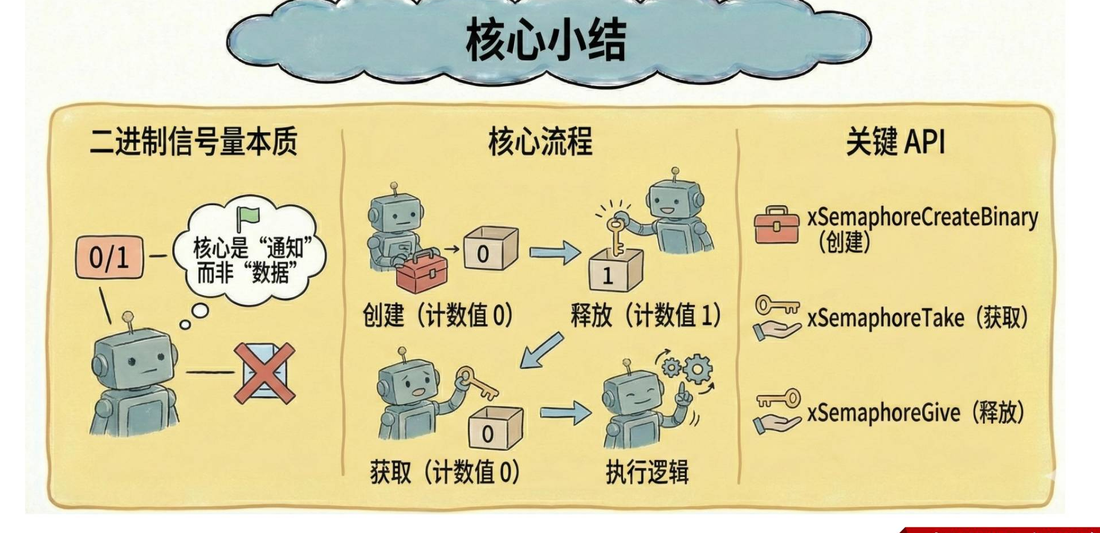

二值信号量的核心可以压缩为三句话：它的计数范围是0/1，主要传递通知而不是业务数据；创建后默认计数值为0，Give 使其可用，Take 成功后计数值回到0；任务等待事件时可以阻塞休眠，事件发生后由发送方唤醒接收方。

在课程工程中可以按下面的顺序检查：

1. 确认信号量创建成功，并在任务使用前完成初始化。
2. 标明 Give 方和 Take 方，画出事件方向，避免两边都在等待而没有发送者。
3. 根据业务选择 `0`、有限 tick 或 `portMAX_DELAY`，并检查超时返回值。
4. 确认二值信号量只承担通知/同步；需要数据或事件计数时改用消息队列或计数信号量。
5. 确认 ISR 中使用 `FromISR` 版本，中断优先级合法，并按需要触发高优先级任务切换。
6. 检查句柄作用域、动态内存空间、删除时机和任务等待关系。
7. 对按键案例增加消抖和重复事件策略，分别核对“每次事件翻转”和“首次事件启动持续闪烁”的预期行为。

本篇依据 `17二值信号量.pptx` 主课件和同名副本的核心小结整理，未进行开发板编译、下载或运行。
